# 14 · Q4 stores and geography: distance to landfall, outliers, chart

Distance is measured to one assumed Big Bend landfall point (no storm-track file was supplied). Outliers are stores whose surge multiple is 1.5 or more standard deviations from the store average. n=12 stores, so this is descriptive.

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = next(d for d in ('data', '../data', '../../data') if os.path.isdir(d))
MISSING_TOKENS = {'', 'null', 'n/a', 'na', 'nan', 'none'}
DECISION_LOG = []

def log_decision(step, decision, rows_touched, rows_before=None, rows_after=None):
    DECISION_LOG.append({'step': step, 'decision': decision, 'rows_touched': int(rows_touched),
                         'rows_before': rows_before, 'rows_after': rows_after})


In [2]:
CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
              '%d-%b-%Y %H:%M', '%m-%d-%Y %H:%M:%S']

def load_transactions():
    return pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)

def standardize_missing(df):
    """Strip whitespace; turn '', NULL, N/A, NaN... into real NaN."""
    out = df.copy()
    touched = 0
    for c in out.columns:
        s = out[c].str.strip()
        newly_na = s.str.lower().isin(MISSING_TOKENS) & out[c].notna()
        touched += int(newly_na.sum())
        out[c] = s.mask(newly_na)
    log_decision('missing', 'strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)', touched, len(df), len(out))
    return out

def remove_duplicates(df):
    n0 = len(df)
    out = df.drop_duplicates()
    log_decision('duplicates', 'drop exact duplicate rows (keep first)', n0 - len(out), n0, len(out))
    n1 = len(out)
    out = out.drop_duplicates('transaction_id')
    log_decision('duplicates', 'drop repeated transaction_id (keep first)', n1 - len(out), n1, len(out))
    return out

def clean_unit_price(df):
    out = df.copy()
    raw = out['unit_price']
    dollar = int(raw.str.contains('$', regex=False, na=False).sum())
    out['unit_price'] = pd.to_numeric(raw.str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    bad = int(out['unit_price'].isna().sum() - raw.isna().sum())
    log_decision('unit_price', "remove '$', cast text -> float", dollar, len(df), len(out))
    log_decision('unit_price', 'values that still failed numeric cast -> NaN', bad, len(df), len(out))
    return out

def clean_quantity(df):
    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    n0 = len(out)
    out = out[out['quantity'] > 0]
    log_decision('quantity', 'drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed)', n0 - len(out), n0, len(out))
    return out

def parse_timestamps(df):
    out = df.copy()
    ts = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        todo = ts.isna() & out['timestamp'].notna()
        ts[todo] = pd.to_datetime(out.loc[todo, 'timestamp'], format=fmt, errors='coerce')
    unparsed = int((ts.isna() & out['timestamp'].notna()).sum())
    missing = int(out['timestamp'].isna().sum())
    out['timestamp'] = ts
    log_decision('timestamp', f'parse {len(TS_FORMATS)} mixed formats into one datetime (naive local time); {unparsed} unparseable', int(ts.notna().sum()), len(df), len(out))
    log_decision('timestamp', 'missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed', missing, len(df), len(out))
    return out

def clean_store_id(df):
    out = df.copy()
    raw = out['store_id']
    out['store_id'] = (raw.str.upper().str.replace('_', '-', regex=False)
                          .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    log_decision('store_id', "uppercase, strip, '_'/missing '-' -> canonical 'FL-###'", int((raw != out['store_id']).sum()), len(df), len(out))
    return out

def clean_category(df):
    out = df.copy()
    raw = out['category']
    out['category'] = raw.str.lower().map(CATEGORY_MAP)
    log_decision('category', f'collapse {raw.nunique()} spellings into {out["category"].nunique()} canonical categories', int((raw != out['category']).sum()), len(df), len(out))
    return out

def clean_transactions():
    DECISION_LOG.clear()
    df = load_transactions()
    for step in (standardize_missing, remove_duplicates, clean_unit_price, clean_quantity,
                 parse_timestamps, clean_store_id, clean_category):
        df = step(df)
    df['product_name_raw'] = df['product_name']
    return df.reset_index(drop=True)


In [3]:

def clean_stores():
    s = pd.read_csv(os.path.join(DATA_DIR, 'store_locations.csv'), dtype={'zip_code': str})
    n0 = len(s)
    s['store_id'] = (s['store_id'].str.strip().str.upper().str.replace('_', '-', regex=False)
                     .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    s = s.drop_duplicates('store_id').reset_index(drop=True)
    log_decision('stores', 'canonicalise store_id and drop duplicate store rows', n0 - len(s), n0, len(s))
    changed = int((s['state'] != 'FL').sum())
    s['state'] = 'FL'
    log_decision('stores', "normalise state ('Florida', 'Fla.') to 'FL'", changed, len(s), len(s))
    # Tallahassee has no coordinates; approximate city-centre values filled in (needed for the weather call)
    fill = {'FL-619': (30.4383, -84.2807)}
    for sid, (lat, lon) in fill.items():
        m = (s['store_id'] == sid) & s['latitude'].isna()
        s.loc[m, ['latitude', 'longitude']] = (lat, lon)
    log_decision('stores', 'fill missing lat/lon for Tallahassee (FL-619) with approximate city-centre coordinates', len(fill), len(s), len(s))
    return s


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

tx_clean = clean_transactions()
dated = tx_clean.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
print('rows used (have a timestamp):', len(dated), 'of', len(tx_clean))


rows used (have a timestamp): 24521 of 25402


In [5]:
BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))   # same windows as Q1
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))

stores = clean_stores()
units = dated.groupby(['store_id', 'day'])['quantity'].sum().unstack('store_id')
assert units.shape == (30, 12), units.shape          # 30 days x 12 stores, nothing lost in the join
base = units.loc[BASELINE[0]:BASELINE[1]].mean()
surge = units.loc[SURGE[0]:SURGE[1]].mean()
ratio = units / base                                  # each day vs that store's own baseline
after16 = ratio.loc['2024-09-16':]
assert (after16 >= 2).any().all(), 'a store never reached 2x baseline'

q4 = pd.DataFrame({'baseline_avg': base, 'surge_avg': surge, 'multiple': surge / base})
q4['first_day_2x'] = (after16 >= 2).idxmax().dt.date  # first day at or above 2x its own baseline
q4['peak_day'] = units.idxmax().dt.date
q4 = q4.join(stores.set_index('store_id')[['city', 'latitude', 'longitude']])
print('first day any store hit 2x:', q4['first_day_2x'].min(), '| last store to hit it:', q4['first_day_2x'].max())
q4.round(2).sort_values('multiple', ascending=False)


first day any store hit 2x: 2024-09-21 | last store to hit it: 2024-09-22


,baseline_avg,surge_avg,multiple,first_day_2x,peak_day,city,latitude,longitude
store_id,,,,,,,,
FL-330,86.73,235.43,2.71,2024-09-21,2024-09-24,Miami,25.76,-80.19
FL-619,86.13,224.14,2.60,2024-09-21,2024-09-24,Tallahassee,30.44,-84.28
FL-105,91.73,231.71,2.53,2024-09-21,2024-09-25,Tampa,27.95,-82.46
FL-412,89.47,222.86,2.49,2024-09-21,2024-09-25,Jacksonville,30.33,-81.66
FL-302,96.27,239.43,2.49,2024-09-21,2024-09-25,Lakeland,28.04,-81.95
FL-445,94.53,232.00,2.45,2024-09-21,2024-09-24,St. Petersburg,27.77,-82.64
FL-710,93.40,227.86,2.44,2024-09-21,2024-09-25,Pensacola,30.42,-87.22
FL-287,91.07,220.14,2.42,2024-09-21,2024-09-25,Kissimmee,28.29,-81.41
FL-156,94.93,229.14,2.41,2024-09-21,2024-09-24,Daytona Beach,29.21,-81.02


surge multiple range: 2.23x - 2.71x | correlation with distance (n=12): r=0.25
outliers (|z| >= 1.5): {'FL-239': {'city': 'Orlando', 'multiple': 2.23}, 'FL-330': {'city': 'Miami', 'multiple': 2.71}}
days to first 2x, by distance rank:
                    city  km_to_landfall first_day_2x
store_id                                             
FL-619       Tallahassee            70.0   2024-09-21
FL-078       Gainesville           154.0   2024-09-22
FL-412      Jacksonville           221.0   2024-09-21
FL-105             Tampa           257.0   2024-09-21
FL-445    St. Petersburg           266.0   2024-09-21
FL-302          Lakeland           279.0   2024-09-21
FL-239           Orlando           286.0   2024-09-21
FL-156     Daytona Beach           287.0   2024-09-21
FL-287         Kissimmee           299.0   2024-09-21
FL-710         Pensacola           324.0   2024-09-21
FL-501        Fort Myers           411.0   2024-09-21
FL-330             Miami           582.0   2024-09-21


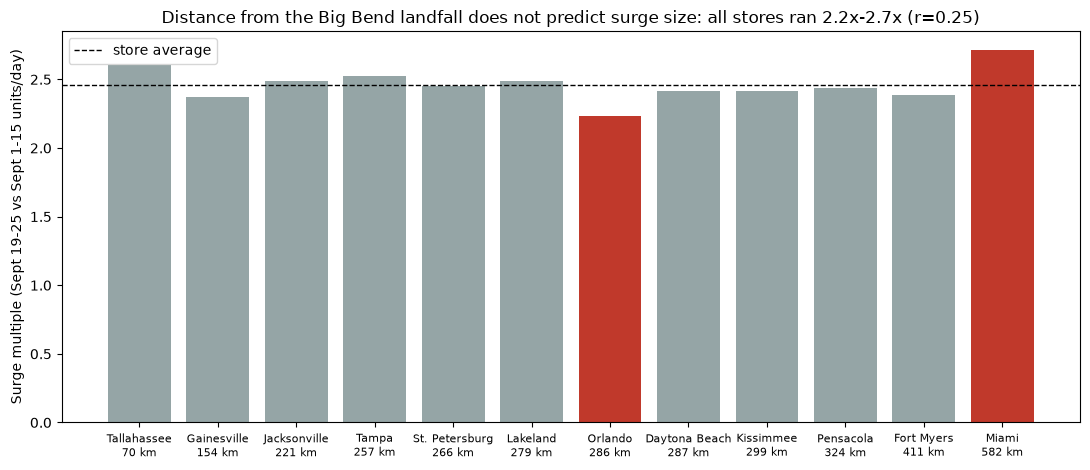

In [6]:
# Assumption: the storm track is represented by one landfall point on the Big Bend coast (approx.), since no track file was supplied.
LANDFALL = (29.9, -83.9)
lat0 = np.radians(LANDFALL[0])
q4['km_to_landfall'] = np.hypot((q4['latitude'] - LANDFALL[0]) * 111,
                                (q4['longitude'] - LANDFALL[1]) * 111 * np.cos(lat0)).round(0)

z = (q4['multiple'] - q4['multiple'].mean()) / q4['multiple'].std()
q4['outlier'] = z.abs() >= 1.5
r = q4['multiple'].corr(q4['km_to_landfall'])
print(f'surge multiple range: {q4["multiple"].min():.2f}x - {q4["multiple"].max():.2f}x | correlation with distance (n=12): r={r:.2f}')
print('outliers (|z| >= 1.5):', q4.loc[q4['outlier'], ['city', 'multiple']].round(2).to_dict('index'))
print('days to first 2x, by distance rank:'); print(q4.sort_values('km_to_landfall')[['city', 'km_to_landfall', 'first_day_2x']].to_string())

ordered = q4.sort_values('km_to_landfall')
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(ordered['city'] + '\n' + ordered['km_to_landfall'].astype(int).astype(str) + ' km', ordered['multiple'],
       color=np.where(ordered['outlier'], '#c0392b', '#95a5a6'))
ax.axhline(q4['multiple'].mean(), color='k', ls='--', lw=1, label='store average')
ax.set_ylabel('Surge multiple (Sept 19-25 vs Sept 1-15 units/day)')
ax.set_title(f'Distance from the Big Bend landfall does not predict surge size: all stores ran {q4["multiple"].min():.1f}x-{q4["multiple"].max():.1f}x (r={r:.2f})')
ax.legend(); plt.xticks(fontsize=8); plt.tight_layout(); plt.show()


**Q4 answer.** No: the stores do not show a geographic pattern. Stores nearer the assumed Big Bend landfall did not spike earlier (11 of 12 hit 2x on Sept 21, including Miami, the farthest at 582 km) or bigger (r=0.25 with distance, if anything slightly the wrong way, n=12). The outliers are Miami (2.71x, high) and Orlando (2.23x, low), and neither is near the landfall point. Caveat: the landfall point is an assumption (no track file was supplied) and the data is synthetic, so small store differences are probably noise.